<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/%5BLAB%5D_DSA211_08_Lab_Model_Selection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Part 0: Setup and Data

We use the `Credit` dataset, familiar from Weeks 2–4: 400 individuals, with credit card `Balance` as the outcome and 11 predictors after dummy encoding. You diagnosed Rating–Limit collinearity (VIF $\approx 161$) in Lab 4. This week you will see how selection methods handle it.

EDA is omitted. Refer to Lab 2 for a full exploration.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import time
from itertools import combinations
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(2026)

In [ ]:
url = "https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Credit.csv"
Credit = pd.read_csv(url).drop(columns='ID')
Credit = pd.get_dummies(Credit,
                        columns=['Gender', 'Student', 'Married', 'Ethnicity'],
                        drop_first=True, dtype=int)
Credit.index = range(1, len(Credit) + 1)

X = Credit.drop(columns='Balance')
y = Credit['Balance']
n, p = X.shape
print(f"n = {n}, p = {p} candidate predictors")
print(list(X.columns))

n = 400, p = 11 candidate predictors
['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Education', 'Gender_Female', 'Student_Yes', 'Married_Yes', 'Ethnicity_Asian', 'Ethnicity_Caucasian']


***

## Part 1: Forward Stepwise Selection

The function below is the same one from the lecture. It implements the forward stepwise selection algorithm on whatever data it is passed, returning the entry order and the fitted model at each size along the path. We use it here on the full data. Part 4 calls it again inside each CV fold.

### 1.1 The Forward Path

In [ ]:
def forward_stepwise(X_train, y_train):
    """Forward stepwise on the given data. Returns entry order and fitted path."""
    remaining = list(X_train.columns)
    selected, path = [], []
    while remaining:
        best_var = min(remaining, key=lambda v: sm.OLS(
            y_train, sm.add_constant(X_train[selected + [v]])).fit().ssr)
        selected.append(best_var)
        remaining.remove(best_var)
        path.append(sm.OLS(y_train, sm.add_constant(X_train[selected])).fit())
    return selected, path

# Feed the X and y to the helper
order, path = forward_stepwise(X, y)

entry = pd.DataFrame({
    'step': range(1, p + 1),
    'variable added': order,
    'R2': [m.rsquared for m in path]
}).set_index('step')
entry.round(4)

,variable added,R2
step,,
1,Rating,0.7458
2,Income,0.8751
3,Student_Yes,0.9499
4,Limit,0.9522
5,Cards,0.9542
6,Age,0.9547
7,Gender_Female,0.9548
8,Ethnicity_Asian,0.9549
9,Married_Yes,0.9550


❓ **Question 1.1a.** `Rating` enters at step 1 and `Limit` enters at step 4. In Lab 4 you found these two have high VIF values. Why does forward stepwise include *both* despite their near-perfect collinearity? Would you expect best subset selection to make the same choice?

*Your answer here:*

Rating and Limit are both highly corrlated with each other, hence, the near-perfect collinearity. I believe that the forward stepwise include both predictors because of their individual reduction in RSS.

Moreover, it's because forward stepwise is **greedy**. Rating has high predictive power, and is added first; however, every variable following will be added to the existing model with Rating, even if another model-combination is more robust. At step 4, Limit is added because it explains the high variance that Rating had already accounted for (high correlation). Because variables are **added**, not **removed** due to the greedy nature of forward stepwise, both Rating and Limit are included.

I do **not** expect best subset selection to make the same choice as it evaluates all possible combination of predictors to choose the most robust one, rather than being bounded by the previous addition of predictors. Perhaps, the best possible combination may include either Rating or Limit, or none at all.


❓ **Question 1.1b.** $R^2$ jumps from 0.75 to 0.88 to 0.95 over the first three steps, then barely moves. What does this plateau tell you about how many predictors matter for predicting `Balance`?

*Your answer here:*

This plateau indicates that predictors following the first 3 does not add as much explanatory power of the total variance as the first 3, which, perhaps, their addition isn't as significant in predicting Balance.

### 1.2 Backward Stepwise

Backward stepwise runs the search in reverse. Start from the full model and at each step delete the predictor whose removal increases RSS the least.

Below we give a function `backward_stepwise(X_train, y_train)` that implements backward stepwise selection. It returns the *deletion* order and the fitted path. We run it on `X, y` and show which predictor each step drops.

In [ ]:
def backward_stepwise(X_train, y_train):
    """Backward stepwise on the given data. Returns deletion order and fitted path."""
    selected = list(X_train.columns)
    path = [sm.OLS(y_train, sm.add_constant(X_train[selected])).fit()]
    deletion_order = []
    while len(selected) > 1:
        worst = min(selected, key=lambda v: sm.OLS(
            y_train, sm.add_constant(X_train[[s for s in selected if s != v]])).fit().ssr)
        deletion_order.append(worst)
        selected.remove(worst)
        path.append(sm.OLS(y_train, sm.add_constant(X_train[selected])).fit())
    deletion_order.append(selected[0])
    return deletion_order, path

del_order, bpath = backward_stepwise(X, y)

pd.DataFrame({'dropped': del_order,
              'predictors left': range(p - 1, -1, -1)},
             index=pd.RangeIndex(1, p+1, name='step'))

,dropped,predictors left
step,,
1,Education,10
2,Ethnicity_Caucasian,9
3,Married_Yes,8
4,Ethnicity_Asian,7
5,Gender_Female,6
6,Age,5
7,Rating,4
8,Cards,3
9,Student_Yes,2


> Step 11 is not a real backward decision, since there’s only one predictor to remove.

❓ **Question 1.2.** Compare backward stepwise's size-5 and size-4 models with forward stepwise's in Part 1.1. Where do the two paths part company, and why does backward drop `Rating` when forward picked it first?

*Your answer here:*

Backward stepwise's size 5 model is: Limit, Income, Student_Yes, Cards, Ratings

Backward stepwise's size 4 model is: Limit, Income, Student_Yes, Cards

Forward stepwise's size 5 model is: Rating, Income, Student_Yes, Limit, Cards

There are no differences in backward stepwise's and forward stepwise's size 5 and size 4 models predictors - the predictors remain are the same. Granted, the order of removal/addition of these predictors differ. When forward stepwise add Rating first, we'd expect for backward stepwise to remove the predictor last; however, this isn't the case where Rating was removed was dropped 5th last.

Backward dropped Rating when forward picked it first because forward stepwise is greedy whereas backward stepwise analyzes all possible predictors combinations. Specifically, forward stepwise chose Rating first because it correlates most with Balance, and Limit follows for the same reason. Backward stepwise sees that Rating and Limit are almost perfectly collinear so adding both are highly redundant; if Rating is already in the model, Limit isn't necessary, and vice, versa.

***

## Part 2: Criterion-Based Selection

The forward path gives us 11 candidate models, one per size. We now compute $C_p$, AIC, BIC, and adjusted $R^2$ for each model along the forward path, and produce a $2 \times 2$ grid of plots as in the lecture. We mark the optimum on each panel and report how many predictors each criterion selects.

> *Note:* $\hat{\sigma}^2$ for $C_p$ is estimated from the full model: `path[-1].ssr / (n - p - 1)`. AIC and BIC are attributes of each fitted model (`.aic`, `.bic`). Adjusted $R^2$ is `.rsquared_adj`.

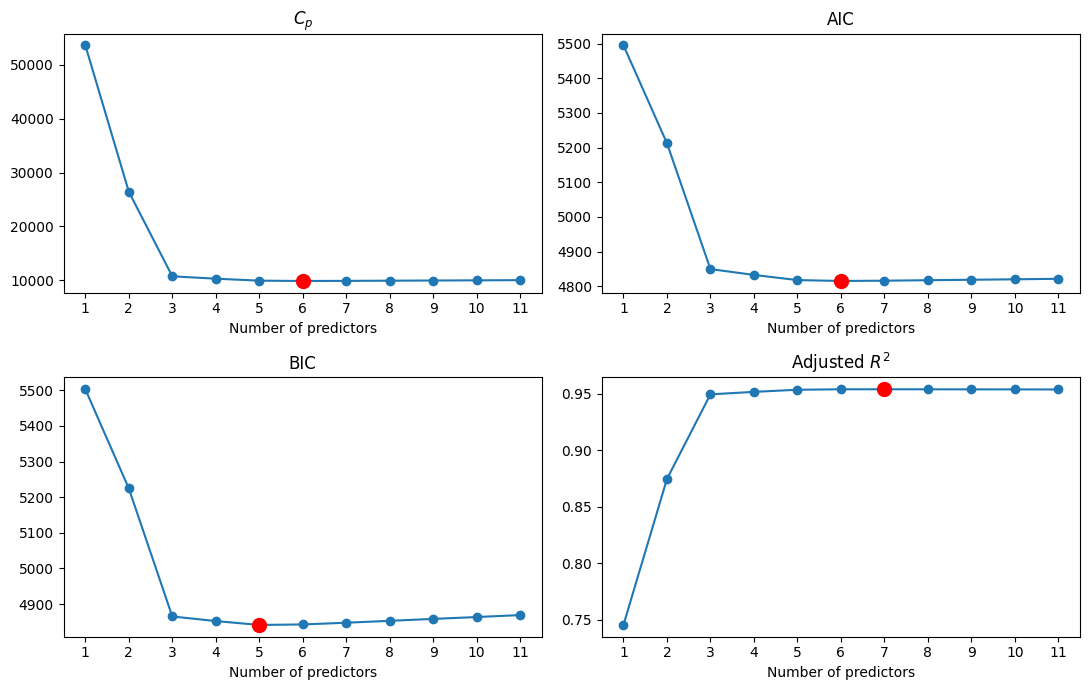

Cp selects          6 predictors
AIC selects         6 predictors
BIC selects         5 predictors
Adjusted R2 selects 7 predictors


In [ ]:
sigma2_hat = path[-1].ssr / (n - p - 1)

d = np.arange(1, p + 1)
rss = np.array([m.ssr for m in path])
Cp  = (rss + 2 * d * sigma2_hat) / n
aic = np.array([m.aic for m in path])
bic = np.array([m.bic for m in path])
adj = np.array([m.rsquared_adj for m in path])

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, vals, name, best in [
    (axes[0, 0], Cp,  r'$C_p$',          np.argmin(Cp)),
    (axes[0, 1], aic, 'AIC',             np.argmin(aic)),
    (axes[1, 0], bic, 'BIC',             np.argmin(bic)),
    (axes[1, 1], adj, r'Adjusted $R^2$', np.argmax(adj)),
]:
    ax.plot(d,
            vals,
            'o-')
    ax.plot(d[best],
            vals[best],
            'ro',
            markersize=10)
    ax.set_xticks(d)
    ax.set_xlabel('Number of predictors')
    ax.set_title(name)
plt.tight_layout()
plt.show()

print(f"Cp selects          {np.argmin(Cp) + 1} predictors")
print(f"AIC selects         {np.argmin(aic) + 1} predictors")
print(f"BIC selects         {np.argmin(bic) + 1} predictors")
print(f"Adjusted R2 selects {np.argmax(adj) + 1} predictors")

In [ ]:
# The BIC-selected model
bic_model = path[np.argmin(bic)]
print("BIC model predictors:", order[:np.argmin(bic) + 1])
bic_model.params.round(2)

BIC model predictors: ['Rating', 'Income', 'Student_Yes', 'Limit', 'Cards']


,0
const,-526.16
Rating,1.09
Income,-7.87
Student_Yes,426.85
Limit,0.19
Cards,17.85


### Exercise 2.1: The AIC model

Print the predictors and coefficient estimates of the model AIC selects. Follow the BIC cell above.

In [ ]:
### YOUR CODE HERE
aic_model = path[np.argmin(aic)]
print("AIC model predictors:", order[:np.argmin(aic) + 1])
aic_model.params.round(2)

BIC_model = sm.OLS(y, sm.add_constant(X[order[:5]])).fit()
AIC_model = sm.OLS(y, sm.add_constant(X[order[:6]])).fit()

print(f"The R^2 of AIC model is {AIC_model.rsquared} and adjusted R^2 is {AIC_model.rsquared_adj}")
print(f"The R^2 of BIC model is {BIC_model.rsquared} and adjusted R^2 is {BIC_model.rsquared_adj}")

AIC model predictors: ['Rating', 'Income', 'Student_Yes', 'Limit', 'Cards', 'Age']
The R^2 of AIC model is 0.9546878863974592 and adjusted R^2 is 0.9539960984035273
The R^2 of BIC model is 0.9541605970612348 and adjusted R^2 is 0.9535788787498292


❓ **Question 2.1.** BIC selects 5 predictors while AIC selects 6. Name the extra variable AIC includes. Is there a meaningful gain in $R^2$ from adding it?

*Your answer here:*

The extra variable that AIC include is Age. The addition of the extra variable of the AIC model does not provide a meaningful increaase in R^2 and adjusted R^2.

***

## Part 3: Best Subset Selection

With $p = 11$ the exhaustive search is feasible: $2^{11} - 1 = 2{,}047$ models. We use the shortcut from the lecture to keep it fast.

### 3.1 Best Subsets on Credit

In [ ]:
Xc  = sm.add_constant(X).to_numpy(dtype=float)
yv  = y.to_numpy(dtype=float)
XtX = Xc.T @ Xc
Xty = Xc.T @ yv
yty = yv @ yv
names = ['const'] + list(X.columns)

def fast_rss(idx):
    """RSS via the normal-equations identity. Intercept at position 0."""
    idx = list(idx)
    beta = np.linalg.solve(XtX[np.ix_(idx, idx)], Xty[idx])
    return yty - beta @ Xty[idx]

t0 = time.time()
best_subset = {}
for k in range(1, p + 1):
    best_rss, best_combo = np.inf, None
    for combo in combinations(range(1, p + 1), k):
        rss = fast_rss((0,) + combo)
        if rss < best_rss:
            best_rss, best_combo = rss, combo
    best_subset[k] = [names[i] for i in best_combo]
elapsed = time.time() - t0

print(f"Searched {2**p - 1:,} models in {elapsed:.2f} s")
for k in range(1, p+1):
    print(f"k = {k}: {best_subset[k]}")

Searched 2,047 models in 0.13 s
k = 1: ['Rating']
k = 2: ['Income', 'Rating']
k = 3: ['Income', 'Rating', 'Student_Yes']
k = 4: ['Income', 'Limit', 'Cards', 'Student_Yes']
k = 5: ['Income', 'Limit', 'Rating', 'Cards', 'Student_Yes']
k = 6: ['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Student_Yes']
k = 7: ['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Gender_Female', 'Student_Yes']
k = 8: ['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Gender_Female', 'Student_Yes', 'Ethnicity_Asian']
k = 9: ['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Gender_Female', 'Student_Yes', 'Married_Yes', 'Ethnicity_Asian']
k = 10: ['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Gender_Female', 'Student_Yes', 'Married_Yes', 'Ethnicity_Asian', 'Ethnicity_Caucasian']
k = 11: ['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Education', 'Gender_Female', 'Student_Yes', 'Married_Yes', 'Ethnicity_Asian', 'Ethnicity_Caucasian']


### Exercise 3.1: The two size-4 models

Fit the best-subset model at $k = 4$ with `sm.OLS` and compare it with the forward-stepwise model at $k = 4$, which is `path[3]`. Show $R^2$ and BIC for both in one table.

In [ ]:
### YOUR CODE HERE
# 1. Fit sm.OLS on X[best_subset[4]] (add a constant)
# 2. Take the forward model at k = 4 from path
# 3. One DataFrame: rows R2 and BIC, one column per model



best_subset_model = sm.OLS(y, sm.add_constant(X[best_subset[4]])).fit()
forward_stepwise_model = path[3]

comparison = pd.DataFrame({
  'Best Subset model': [best_subset_model.rsquared, best_subset_model.bic],
  'Forward Stepwise model': [forward_stepwise_model.rsquared, forward_stepwise_model.bic]
}, index=['R^2', 'BIC'])

print(comparison)

print(best_subset_model.params.index, forward_stepwise_model.params.index)


     Best Subset model  Forward Stepwise model
R^2            0.95358                0.952188
BIC         4840.65866             4852.481331
Index(['const', 'Income', 'Limit', 'Cards', 'Student_Yes'], dtype='object') Index(['const', 'Rating', 'Income', 'Student_Yes', 'Limit'], dtype='object')


In [ ]:
for index, model in enumerate(path):
    # Extract predictor names (excluding the intercept 'const')
    predictors = [var for var in model.params.index if var != 'const']
    print(f"path[{index}] -> Model Size (k) = {len(predictors)} | Predictors: {predictors}")

path[0] -> Model Size (k) = 1 | Predictors: ['Rating']
path[1] -> Model Size (k) = 2 | Predictors: ['Rating', 'Income']
path[2] -> Model Size (k) = 3 | Predictors: ['Rating', 'Income', 'Student_Yes']
path[3] -> Model Size (k) = 4 | Predictors: ['Rating', 'Income', 'Student_Yes', 'Limit']
path[4] -> Model Size (k) = 5 | Predictors: ['Rating', 'Income', 'Student_Yes', 'Limit', 'Cards']
path[5] -> Model Size (k) = 6 | Predictors: ['Rating', 'Income', 'Student_Yes', 'Limit', 'Cards', 'Age']
path[6] -> Model Size (k) = 7 | Predictors: ['Rating', 'Income', 'Student_Yes', 'Limit', 'Cards', 'Age', 'Gender_Female']
path[7] -> Model Size (k) = 8 | Predictors: ['Rating', 'Income', 'Student_Yes', 'Limit', 'Cards', 'Age', 'Gender_Female', 'Ethnicity_Asian']
path[8] -> Model Size (k) = 9 | Predictors: ['Rating', 'Income', 'Student_Yes', 'Limit', 'Cards', 'Age', 'Gender_Female', 'Ethnicity_Asian', 'Married_Yes']
path[9] -> Model Size (k) = 10 | Predictors: ['Rating', 'Income', 'Student_Yes', 'Limit',

❓ **Question 3.1.** Compare the best subset model at $k = 4$ with the forward stepwise model at $k = 4$. Which variables differ? Connect this to the Rating–Limit collinearity from Lab 4. Why can best subset find a combination that forward stepwise cannot?

*Your answer here:*

The forward stepwise model includes predictor **Rating** whilst the best subset model does not with both models at k=4.

This occurs due to collinearity from Lab 4 and also a drawback from the forward stepwise model itself. Specifically, the forward stepwise model is **greedy** and nested, predictors that are accounted in the model cannot be removed even if another another variations of predictors results in lower test MSE. In the forward stepwise model, perhaps **Limits** is added because it's highly correlated with Rating - they carry the same information.

Best subset can find a combination that forward stepwise cannot is also due to the latter's greediness. Its models are nested - once a predictor is added, it can't ever be removed. So, eventhough predictor **Cards** should be added to the model, as Rating has already been chosen and following models are nested, Cards wasn't added to the forward stepwise model.

### 3.2 Best Subset and BIC

Below we refit the best subset winners in `statsmodels`, compute BIC for each size, and report which size BIC selects. We also add forward stepwise winners as a comparison.

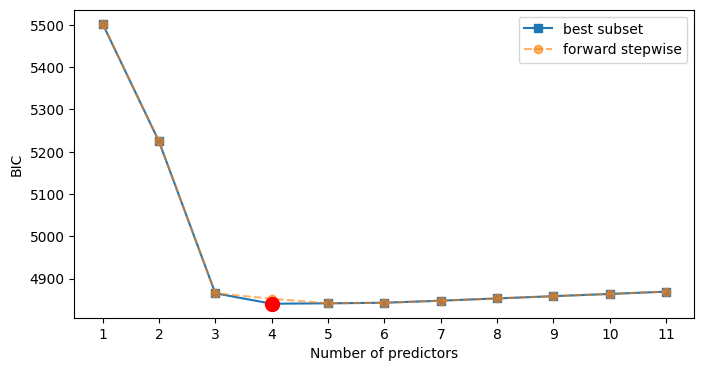

Best-subset BIC selects 4 predictors: ['Income', 'Limit', 'Cards', 'Student_Yes']
BIC at k = 4: best subset 4840.7, forward stepwise 4852.5
Forward-step BIC selects 5 predictors: ['Rating', 'Income', 'Student_Yes', 'Limit', 'Cards']


In [ ]:
best_models = {k: sm.OLS(y, sm.add_constant(X[best_subset[k]])).fit()
               for k in best_subset}

bic_bs = np.array([best_models[k].bic for k in range(1, p + 1)])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(d,
        bic_bs,
        's-',
        label='best subset')
ax.plot(d,
        bic,
        'o--',
        alpha=0.6,
        label='forward stepwise')
ax.plot(np.argmin(bic_bs) + 1,
        bic_bs[np.argmin(bic_bs)],
        'ro',
        markersize=10)
ax.set_xticks(d)
ax.set_xlabel('Number of predictors')
ax.set_ylabel('BIC')
ax.legend()
plt.show()

k_bic_bs = np.argmin(bic_bs) + 1
print(f"Best-subset BIC selects {k_bic_bs} predictors: {best_subset[k_bic_bs]}")
print(f"BIC at k = 4: best subset {bic_bs[3]:.1f}, forward stepwise {bic[3]:.1f}")
print(f"Forward-step BIC selects {np.argmin(bic) + 1} predictors: {order[:np.argmin(bic) + 1]}")

❓ **Question 3.2.** At every model size from $k = 1$ onwards, do the best-subset BIC values sit below or above the forward-stepwise BIC values? Must this always be the case? Why?

*Your answer here:*

The best-subset BIC value sit below the forward-stepwise BIC values; this is not always the case. The difference in BIC between the two model is most apaprent when model size is 4 predictors; however, in other model sizes, BIC appears to be alike. Hence, the best-subset BIC is always below or equalt to forward-stepwise BIC value. This is due to the inherent natuer of best subset selction - it exhaustively finds all possible combination of predictors and chooses one with least possible test MSE, whereas forward stepwise doesn't always find the best (least test MSE) combination of predictors.

Therefore, it must be true that best subset selection BIC value is always lower or equal to forward stepwise BIC value.

***

## Part 4: Cross-Validation for Model Selection

As established in the lecture, the search must go inside the CV loop. Whatever is learned from the data must be learned inside the fold. We cross-validate the *procedure* "forward stepwise stopped at size $k$", not any single fixed model. Identify how the lines of the chunk below relate to the illustration table in the lecture (Section 5.1).

In [ ]:
kf = KFold(n_splits=10,
           shuffle=True,
           random_state=2026)

fold_err = np.zeros((kf.get_n_splits(), p)) # empty (K x p) matrix
for f, (train_idx, test_idx) in enumerate(kf.split(X)): # fold
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_te, y_te = X.iloc[test_idx],  y.iloc[test_idx]

    order_f, path_f = forward_stepwise(X_tr, y_tr) # forward fold path on training data
    for k in range(1, p + 1):
        pred = path_f[k - 1].predict(
            sm.add_constant(X_te[order_f[:k]], has_constant='add'))
        fold_err[f, k - 1] = mean_squared_error(y_te, pred) # compute MSE along the fold path

cv_mean = fold_err.mean(axis=0) # mean CV error for each size
cv_se   = fold_err.std(axis=0, ddof=1) / np.sqrt(kf.get_n_splits()) # s/sqrt(K)

k_min = int(np.argmin(cv_mean)) + 1 # index starts at 0
print(f"CV error is minimised at {k_min} predictors")

CV error is minimised at 6 predictors


### 4.1 The One-Standard-Error Rule

Below we apply the one-standard-error rule:

1. Find the smallest $k$ whose CV error is within one SE of the minimum.
2. Plot the CV curve with error bars, the threshold line, and both the minimum and the one-SE choice marked.

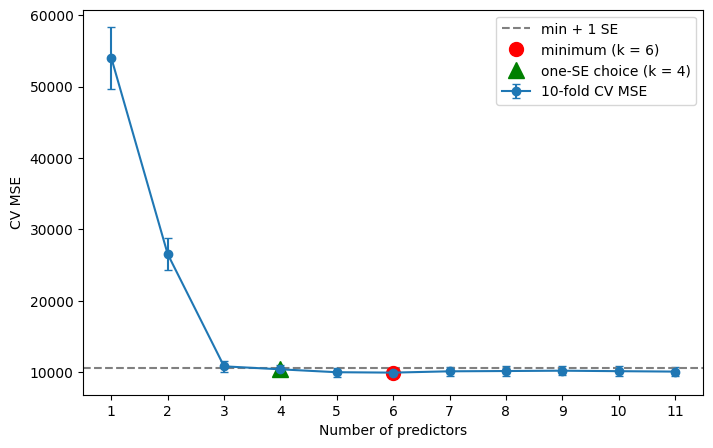

One-SE model (k = 4): ['Rating', 'Income', 'Student_Yes', 'Limit']


In [ ]:
threshold = cv_mean[k_min - 1] + cv_se[k_min - 1] # mean + 1se
k_1se = int(np.argmax(cv_mean <= threshold)) + 1 # counting starts from 0

plt.figure(figsize=(8, 5))
plt.errorbar(d,
             cv_mean,
             yerr=cv_se,
             fmt='o-',
             capsize=3,
             label='10-fold CV MSE')
plt.axhline(threshold,
            color='grey',
            linestyle='--',
            label='min + 1 SE')
plt.plot(k_min, cv_mean[k_min - 1],
         'ro',
         markersize=10,
         label=f'minimum (k = {k_min})')
plt.plot(k_1se, cv_mean[k_1se - 1],
         'g^',
         markersize=12,
         label=f'one-SE choice (k = {k_1se})')
plt.xticks(d)
plt.xlabel('Number of predictors')
plt.ylabel('CV MSE')
plt.legend()
plt.show()

print(f"One-SE model (k = {k_1se}): {order[:k_1se]}")

### Exercise 4.1: What the one-SE rule gives up

Show, in one table, the CV MSE at $k_{\min}$ and at $k_{1\text{SE}}$, their difference, and the SE at $k_{\min}$.

In [ ]:
### YOUR CODE HERE
# cv_mean and cv_se start at position 0, so size k sits at position k - 1

table = pd.DataFrame({
    'Mean CV error': [cv_mean[5], cv_mean[3], cv_mean[5] - cv_mean[3]],
    'CV Standard error': [cv_se[5], cv_se[3], cv_se[5] - cv_se[3]],
}, index=['k_min', 'k_1_se', 'difference'])



print(table)

            Mean CV error  CV Standard error
k_min         9962.282313         644.071601
k_1_se       10424.624353         628.592149
difference    -462.342040          15.479451


❓ **Question 4.1.** The one-SE model drops `Cards` and `Age` from the CV-minimum model. Is the increase in CV MSE large compared with the SE? What do you gain in exchange?

*Your answer here:*

I believe it's a large increase in CV MSE, but still within the error bars of the model with size 6. In exchange, I believe that we have a simpler model which decreases model's complexity and the possibility of overfitting the model.

### 4.2 The Final Model

### Exercise 4.2: The final model

Produce the final model: stop the full-data forward path at the one-SE size and display the coefficient estimates. The Part 1 path was searched on the full data, so it is reused here. No new search is needed.

In [ ]:
### YOUR CODE HERE
# 1. Reuse order and path from Part 1 (the full-data search)
# 2. Extract the model at position k_1se - 1 from the path
# 3. Print the variables and the coefficient estimates

#I use forward_stepwise from above which is = path[k_1se -1] = path[3]
print(f'The full model contains predictors {[col for col in forward_stepwise_model.params.index if col != 'const']} and coefficient estimates {forward_stepwise_model.params}')




The full model contains predictors ['Rating', 'Income', 'Student_Yes', 'Limit'] and coefficient estimates const         -516.718261
Rating           2.190439
Income          -7.944634
Student_Yes    422.668379
Limit            0.121682
dtype: float64
Index(['const', 'Rating', 'Income', 'Student_Yes', 'Limit', 'Cards', 'Age',
       'Gender_Female'],
      dtype='object')


***

## Part 5: Comparing Selection Strategies

### 5.1 The Selected Models

### Exercise 5.1: The comparison table

In [ ]:
forward_stepwise_CV = path[k_min]

print(forward_stepwise_CV.params.index)

Index(['const', 'Rating', 'Income', 'Student_Yes', 'Limit', 'Cards', 'Age',
       'Gender_Female'],
      dtype='object')


The table below summarises the models selected by each method in this lab.

| Method | Size | Variables |
|---|---|---|
| Forward stepwise + AIC | 6 | 'Rating', 'Income', 'Student_Yes', 'Limit', 'Cards', 'Age' |
| Forward stepwise + BIC | 5 | Rating', 'Income', 'Student_Yes', 'Limit', 'Cards |
| Forward stepwise + CV (min) | 6 | 'Rating', 'Income', 'Student_Yes', 'Limit', 'Cards', 'Age', 'Gender_Female'|
| Forward stepwise + CV (1-SE) | 4 | 'Rating', 'Income', 'Student_Yes', 'Limit' |
| Best subset + BIC | 4 | 'Income', 'Limit', 'Cards', 'Student_Yes' |

Fill in the table from your results above.

### 5.2 Collinearity in the One-SE Model

Below we compute the VIF of each predictor in the one-SE model and in the best-subset model at $k = 4$ and show both in one table.

In [ ]:
def vifs(cols):
    Xm = sm.add_constant(X[cols]).values
    return pd.Series([variance_inflation_factor(Xm, i) for i in range(1, Xm.shape[1])],
                     index=cols)

pd.DataFrame({'one-SE model': vifs(order[:k_1se]),
              'best-subset k = 4': vifs(best_subset[4])}).round(1).fillna('-')

,one-SE model,best-subset k = 4
Cards,-,1.0
Income,2.7,2.7
Limit,161.6,2.7
Rating,161.1,-
Student_Yes,1.0,1.0


❓ **Question 5.2.** The one-SE model contains both `Rating` and `Limit`, which have VIF $\approx 235$ in the full model. Is the collinearity still severe in the one-SE model? What does this tell you about when high VIF is a problem and when it is not?



*Your answer here:*

I think that collinearity is still severe in the one_SE model, it's extremely severe. It implies that VIF is a problem depending on the goal for the model. If it's predictions, correlation and collinearity between predictors will remain accurate as long as the correlations do not change. Moreover, it also implies that VIF is a problem because collinearity affects each individual predictor's coefficient, which may be influenced by another predictor when predictors share the same information.

### 5.3 Prediction or Inference?

❓ **Question 5.3.** If your goal is *prediction*, which model from the table would you choose and why? If your goal is *inference* (understanding which factors drive credit card balance), would your answer change?

*Your answer here:*

If my goal is prediction, I would use any of these models. If the model size is smaller or equal to 20, I would use the best subset model + BIC because it's strict, and I'd receive the model with least test MSE.

If my goal were to be inference, I would not use any of these models because they choose predictors after analyzing the data which overstates standard error and nullifies statistical numbers like p-values.

***

## Lab Checklist

Before submitting, confirm you have:

- [ ] Run all demo cells without errors
- [ ] Answered Questions 1.1a, 1.1b and 1.2
- [ ] Completed Exercise 2.1 (AIC model) and answered Question 2.1
- [ ] Completed Exercise 3.1 (the two size-4 models) and answered Questions 3.1 and 3.2
- [ ] Completed Exercise 4.1 (cost of the one-SE rule) and answered Question 4.1
- [ ] Completed Exercise 4.2 (final model)
- [ ] Completed Exercise 5.1 (comparison table)
- [ ] Answered Questions 5.2 and 5.3